In [8]:
!pip install flwr torch torchvision matplotlib


In [9]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

# Use GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Load MNIST dataset
transform = transforms.ToTensor()

train_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = torchvision.datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

print("Training samples:", len(train_dataset))
print("Testing samples:", len(test_dataset))

Using device: cpu
Training samples: 60000
Testing samples: 10000


In [10]:
# Define our AI model
class MNISTModel(nn.Module):
    def __init__(self):
        super(MNISTModel, self).__init__()

        self.network = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


# Create the global model
global_model = MNISTModel().to(device)

print(global_model)

MNISTModel(
  (network): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [11]:
from torch.utils.data import DataLoader, Subset
import numpy as np

# Number of simulated clients
NUM_CLIENTS = 5

# IID data distribution
indices = np.random.permutation(len(train_dataset))
client_indices = np.array_split(indices, NUM_CLIENTS)

# Create a dataset for each client
client_loaders = []

for i in range(NUM_CLIENTS):
    client_dataset = Subset(
        train_dataset,
        client_indices[i].tolist()
    )

    client_loader = DataLoader(
        client_dataset,
        batch_size=32,
        shuffle=True
    )

    client_loaders.append(client_loader)

    print(f"Client {i+1}: {len(client_dataset)} training samples")


Client 1: 12000 training samples
Client 2: 12000 training samples
Client 3: 12000 training samples
Client 4: 12000 training samples
Client 5: 12000 training samples


In [12]:
import copy

# Train one client's model locally
def train_client(model, train_loader, epochs=1):
    model.train()

    optimizer = optim.SGD(model.parameters(), lr=0.01)
    criterion = nn.CrossEntropyLoss()

    for epoch in range(epochs):
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

    return model.state_dict()


In [13]:
# Federated Averaging
def fed_avg(client_weights):
    global_weights = copy.deepcopy(client_weights[0])

    for key in global_weights.keys():
        for i in range(1, len(client_weights)):
            global_weights[key] += client_weights[i][key]

        global_weights[key] /= len(client_weights)

    return global_weights


In [14]:
# Save the initial global model
global_weights = global_model.state_dict()

client_weights = []

# Train each client locally
for i in range(NUM_CLIENTS):
    local_model = MNISTModel().to(device)
    local_model.load_state_dict(global_weights)

    trained_weights = train_client(
        local_model,
        client_loaders[i],
        epochs=1
    )

    client_weights.append(trained_weights)

    print(f"Client {i+1} completed local training")

# Aggregate client updates
global_weights = fed_avg(client_weights)

# Update global model
global_model.load_state_dict(global_weights)

print("Federated Round 1 completed!")

Client 1 completed local training
Client 2 completed local training
Client 3 completed local training
Client 4 completed local training
Client 5 completed local training
Federated Round 1 completed!


In [15]:
# Create test data loader
test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

# Evaluate global model
def evaluate_model(model, test_loader):
    model.eval()

    correct = 0
    total = 0
    total_loss = 0

    criterion = nn.CrossEntropyLoss()

    with torch.no_grad():
        for images, labels in test_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            total_loss += loss.item()

    accuracy = 100 * correct / total
    avg_loss = total_loss / len(test_loader)

    return accuracy, avg_loss


accuracy, loss = evaluate_model(global_model, test_loader)

print("Global Model Accuracy:", round(accuracy, 2), "%")
print("Global Model Loss:", round(loss, 4))

Global Model Accuracy: 77.7 %
Global Model Loss: 1.2777


In [16]:
# Track experimental results
accuracy_history = [accuracy]
loss_history = [loss]

NUM_ROUNDS = 5

for round_num in range(2, NUM_ROUNDS + 1):

    client_weights = []

    # Local training on each client
    for i in range(NUM_CLIENTS):
        local_model = MNISTModel().to(device)
        local_model.load_state_dict(global_weights)

        trained_weights = train_client(
            local_model,
            client_loaders[i],
            epochs=1
        )

        client_weights.append(trained_weights)

    # Aggregate updates using FedAvg
    global_weights = fed_avg(client_weights)
    global_model.load_state_dict(global_weights)

    # Evaluate global model
    accuracy, loss = evaluate_model(
        global_model,
        test_loader
    )

    accuracy_history.append(accuracy)
    loss_history.append(loss)

    print(
        f"Round {round_num} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f}"
    )

print("\nTraining completed!")

Round 2 | Accuracy: 84.74% | Loss: 0.7017
Round 3 | Accuracy: 87.22% | Loss: 0.5287
Round 4 | Accuracy: 88.57% | Loss: 0.4506
Round 5 | Accuracy: 89.27% | Loss: 0.4054

Training completed!


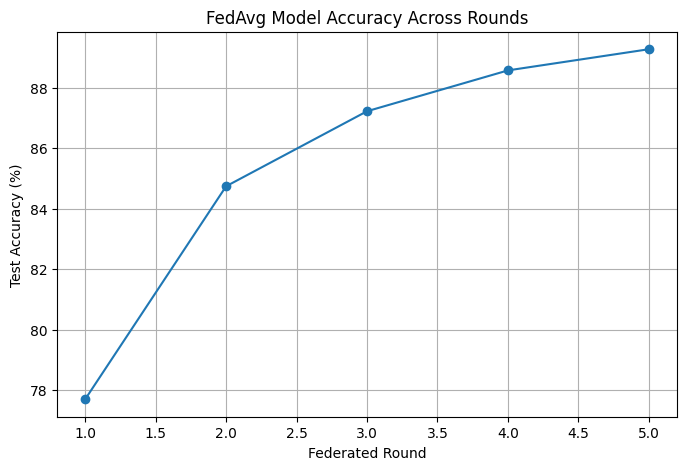

In [17]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, NUM_ROUNDS + 1),
    accuracy_history,
    marker="o"
)

plt.xlabel("Federated Round")
plt.ylabel("Test Accuracy (%)")
plt.title("FedAvg Model Accuracy Across Rounds")
plt.grid(True)

plt.show()

In [18]:
# Create non-IID data distribution
client_indices_noniid = []

targets = train_dataset.targets.numpy()

for i in range(NUM_CLIENTS):

    # Each client receives two digit classes
    classes = [i * 2, i * 2 + 1]

    indices = np.where(np.isin(targets, classes))[0]

    np.random.shuffle(indices)

    client_indices_noniid.append(indices)

    print(
        f"Client {i+1} | Digits: {classes} | "
        f"Samples: {len(indices)}"
    )


# Create DataLoaders
client_loaders_noniid = []

for indices in client_indices_noniid:

    client_dataset = Subset(
        train_dataset,
        indices.tolist()
    )

    loader = DataLoader(
        client_dataset,
        batch_size=32,
        shuffle=True
    )

    client_loaders_noniid.append(loader)

print("Non-IID clients created!")

Client 1 | Digits: [0, 1] | Samples: 12665
Client 2 | Digits: [2, 3] | Samples: 12089
Client 3 | Digits: [4, 5] | Samples: 11263
Client 4 | Digits: [6, 7] | Samples: 12183
Client 5 | Digits: [8, 9] | Samples: 11800
Non-IID clients created!


In [19]:
# Reset model for a fair comparison
global_model_noniid = MNISTModel().to(device)

global_weights_noniid = global_model_noniid.state_dict()

noniid_accuracy_history = []
noniid_loss_history = []

NUM_ROUNDS = 5

for round_num in range(1, NUM_ROUNDS + 1):

    client_weights = []

    for i in range(NUM_CLIENTS):

        local_model = MNISTModel().to(device)

        local_model.load_state_dict(
            global_weights_noniid
        )

        trained_weights = train_client(
            local_model,
            client_loaders_noniid[i],
            epochs=1
        )

        client_weights.append(trained_weights)

    # Aggregate client models
    global_weights_noniid = fed_avg(client_weights)

    global_model_noniid.load_state_dict(
        global_weights_noniid
    )

    # Evaluate
    accuracy, loss = evaluate_model(
        global_model_noniid,
        test_loader
    )

    noniid_accuracy_history.append(accuracy)
    noniid_loss_history.append(loss)

    print(
        f"Non-IID Round {round_num} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f}"
    )

print("Non-IID experiment completed!")

Non-IID Round 1 | Accuracy: 49.83% | Loss: 2.0381
Non-IID Round 2 | Accuracy: 66.57% | Loss: 1.7632
Non-IID Round 3 | Accuracy: 71.14% | Loss: 1.5395
Non-IID Round 4 | Accuracy: 72.95% | Loss: 1.3698
Non-IID Round 5 | Accuracy: 73.58% | Loss: 1.2440
Non-IID experiment completed!


In [21]:
def train_client_fedprox(
    model,
    train_loader,
    global_model,
    epochs=1,
    mu=0.01
):
    model.train()

    optimizer = optim.SGD(
        model.parameters(),
        lr=0.01
    )

    criterion = nn.CrossEntropyLoss()

    # Keep global parameters fixed
    global_params = [
        p.detach().clone()
        for p in global_model.parameters()
    ]

    for epoch in range(epochs):

        for images, labels in train_loader:

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            # Standard classification loss
            loss = criterion(outputs, labels)

            # FedProx regularization
            proximal_term = 0

            for local_param, global_param in zip(
                model.parameters(),
                global_params
            ):
                proximal_term += torch.sum(
                    (local_param - global_param) ** 2
                )

            loss = loss + (mu / 2) * proximal_term

            loss.backward()
            optimizer.step()

    return model.state_dict()

print("FedProx training function ready!")

FedProx training function ready!


In [22]:
# Initialize a fresh global model
fedprox_model = MNISTModel().to(device)

fedprox_weights = fedprox_model.state_dict()

fedprox_accuracy_history = []

NUM_ROUNDS = 5

for round_num in range(1, NUM_ROUNDS + 1):

    client_weights = []

    for i in range(NUM_CLIENTS):

        local_model = MNISTModel().to(device)

        local_model.load_state_dict(fedprox_weights)

        trained_weights = train_client_fedprox(
            local_model,
            client_loaders_noniid[i],
            fedprox_model,
            epochs=1,
            mu=0.01
        )

        client_weights.append(trained_weights)

    # Aggregate client models
    fedprox_weights = fed_avg(client_weights)

    fedprox_model.load_state_dict(fedprox_weights)

    # Evaluate global model
    accuracy, loss = evaluate_model(
        fedprox_model,
        test_loader
    )

    fedprox_accuracy_history.append(accuracy)

    print(
        f"FedProx Round {round_num} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f}"
    )

print("FedProx experiment completed!")

FedProx Round 1 | Accuracy: 45.59% | Loss: 2.0728
FedProx Round 2 | Accuracy: 62.81% | Loss: 1.7977
FedProx Round 3 | Accuracy: 70.39% | Loss: 1.5711
FedProx Round 4 | Accuracy: 72.58% | Loss: 1.3967
FedProx Round 5 | Accuracy: 73.71% | Loss: 1.2665
FedProx experiment completed!


In [23]:
import pandas as pd
import numpy as np

df_phish = pd.read_csv(
    "/content/dataset_B_05_2020.csv"
)

print("Dataset shape:", df_phish.shape)
print(df_phish["status"].value_counts())

Dataset shape: (11430, 89)
status
legitimate    5715
phishing      5715
Name: count, dtype: int64


In [24]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader

# 1. Prepare features and labels
X_phish = df_phish.drop(columns=["url", "status"])
y_phish = df_phish["status"].map({
    "legitimate": 0,
    "phishing": 1
})

# 2. Split into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X_phish,
    y_phish,
    test_size=0.20,
    random_state=42,
    stratify=y_phish
)

# 3. Scale numerical features
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# 4. Convert to PyTorch tensors
X_train = torch.tensor(
    X_train, dtype=torch.float32
)
X_test = torch.tensor(
    X_test, dtype=torch.float32
)

y_train = torch.tensor(
    y_train.values, dtype=torch.long
)
y_test = torch.tensor(
    y_test.values, dtype=torch.long
)

# 5. Create datasets
phish_train_dataset = TensorDataset(
    X_train, y_train
)

phish_test_dataset = TensorDataset(
    X_test, y_test
)

test_loader_phish = DataLoader(
    phish_test_dataset,
    batch_size=64,
    shuffle=False
)

print("Training samples:", len(phish_train_dataset))
print("Testing samples:", len(phish_test_dataset))
print("Number of features:", X_train.shape[1])
print("Data preparation completed!")

Training samples: 9144
Testing samples: 2286
Number of features: 87
Data preparation completed!


In [25]:
NUM_CLIENTS = 5

# Randomly distribute training data among clients
indices = np.random.permutation(
    len(phish_train_dataset)
)

client_indices_phish = np.array_split(
    indices, NUM_CLIENTS
)

client_loaders_phish = []

for i in range(NUM_CLIENTS):

    client_dataset = torch.utils.data.Subset(
        phish_train_dataset,
        client_indices_phish[i].tolist()
    )

    loader = DataLoader(
        client_dataset,
        batch_size=32,
        shuffle=True
    )

    client_loaders_phish.append(loader)

    print(
        f"Client {i+1}: "
        f"{len(client_dataset)} samples"
    )

print("Five phishing clients created!")

Client 1: 1829 samples
Client 2: 1829 samples
Client 3: 1829 samples
Client 4: 1829 samples
Client 5: 1828 samples
Five phishing clients created!


In [26]:
# Neural network for phishing detection
class PhishModel(nn.Module):

    def __init__(self):
        super(PhishModel, self).__init__()

        self.network = nn.Sequential(
            nn.Linear(87, 128),
            nn.ReLU(),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        return self.network(x)


# Initialize global phishing model
phish_global_model = PhishModel().to(device)

print(phish_global_model)

PhishModel(
  (network): Sequential(
    (0): Linear(in_features=87, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=2, bias=True)
  )
)


In [27]:
# Initialize federated phishing model
phish_global_weights = (
    phish_global_model.state_dict()
)

phish_accuracy_history = []
phish_loss_history = []

NUM_ROUNDS = 5

for round_num in range(1, NUM_ROUNDS + 1):

    client_weights = []

    # Train each client locally
    for i in range(NUM_CLIENTS):

        local_model = PhishModel().to(device)

        local_model.load_state_dict(
            phish_global_weights
        )

        trained_weights = train_client(
            local_model,
            client_loaders_phish[i],
            epochs=1
        )

        client_weights.append(
            trained_weights
        )

    # Aggregate using FedAvg
    phish_global_weights = fed_avg(
        client_weights
    )

    phish_global_model.load_state_dict(
        phish_global_weights
    )

    # Evaluate on phishing test data
    accuracy, loss = evaluate_model(
        phish_global_model,
        test_loader_phish
    )

    phish_accuracy_history.append(accuracy)
    phish_loss_history.append(loss)

    print(
        f"PhishGuard Round {round_num} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f}"
    )

print("Federated PhishGuard training completed!")


PhishGuard Round 1 | Accuracy: 75.02% | Loss: 0.6564
PhishGuard Round 2 | Accuracy: 84.03% | Loss: 0.6168
PhishGuard Round 3 | Accuracy: 87.36% | Loss: 0.5630
PhishGuard Round 4 | Accuracy: 89.11% | Loss: 0.4946
PhishGuard Round 5 | Accuracy: 90.24% | Loss: 0.4221
Federated PhishGuard training completed!


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Get predictions from federated model
phish_global_model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for images, labels in test_loader_phish:

        images = images.to(device)

        outputs = phish_global_model(images)

        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())


# Calculate metrics
print("FEDERATED PHISHGUARD RESULTS")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_true, y_pred) * 100, 2), "%")

print("Precision:",
      round(precision_score(y_true, y_pred) * 100, 2), "%")

print("Recall:",
      round(recall_score(y_true, y_pred) * 100, 2), "%")

print("F1-Score:",
      round(f1_score(y_true, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    target_names=["Legitimate", "Phishing"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_true, y_pred))

FEDERATED PHISHGUARD RESULTS
Accuracy: 90.24 %
Precision: 89.66 %
Recall: 90.99 %
F1-Score: 90.32 %

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.91      0.90      0.90      1143
    Phishing       0.90      0.91      0.90      1143

    accuracy                           0.90      2286
   macro avg       0.90      0.90      0.90      2286
weighted avg       0.90      0.90      0.90      2286

Confusion Matrix:
[[1023  120]
 [ 103 1040]]


In [29]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

# Convert tensors back to NumPy
X_train_np = X_train.numpy()
X_test_np = X_test.numpy()

y_train_np = y_train.numpy()
y_test_np = y_test.numpy()

# Train centralized Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_np, y_train_np)

# Predict on the same test set
rf_predictions = rf_model.predict(X_test_np)

# Calculate metrics
rf_accuracy = accuracy_score(
    y_test_np, rf_predictions
) * 100

rf_precision = precision_score(
    y_test_np, rf_predictions
) * 100

rf_recall = recall_score(
    y_test_np, rf_predictions
) * 100

rf_f1 = f1_score(
    y_test_np, rf_predictions
) * 100

print("CENTRALIZED PHISHGUARD — RANDOM FOREST")
print("=" * 45)

print(f"Accuracy:  {rf_accuracy:.2f}%")
print(f"Precision: {rf_precision:.2f}%")
print(f"Recall:    {rf_recall:.2f}%")
print(f"F1-Score:  {rf_f1:.2f}%")

CENTRALIZED PHISHGUARD — RANDOM FOREST
Accuracy:  96.06%
Precision: 95.74%
Recall:    96.41%
F1-Score:  96.08%


In [30]:
# Create non-IID phishing clients
y_train_array = y_train.numpy()

client_indices_noniid_phish = []

for i in range(NUM_CLIENTS):

    # Each client has a different class preference
    dominant_class = i % 2

    dominant_indices = np.where(
        y_train_array == dominant_class
    )[0]

    other_indices = np.where(
        y_train_array != dominant_class
    )[0]

    np.random.shuffle(dominant_indices)
    np.random.shuffle(other_indices)

    # 80% dominant class, 20% other class
    n_dominant = int(1829 * 0.8)
    n_other = 1829 - n_dominant

    selected = np.concatenate([
        dominant_indices[:n_dominant],
        other_indices[:n_other]
    ])

    np.random.shuffle(selected)

    client_indices_noniid_phish.append(selected)

    print(
        f"Client {i+1}: "
        f"{len(selected)} samples | "
        f"Dominant class: {dominant_class}"
    )

print("Non-IID phishing clients created!")

Client 1: 1829 samples | Dominant class: 0
Client 2: 1829 samples | Dominant class: 1
Client 3: 1829 samples | Dominant class: 0
Client 4: 1829 samples | Dominant class: 1
Client 5: 1829 samples | Dominant class: 0
Non-IID phishing clients created!


In [31]:
# Initialize a fresh global model
phish_noniid_model = PhishModel().to(device)

noniid_weights = phish_noniid_model.state_dict()

phish_noniid_accuracy = []
phish_noniid_loss = []

for round_num in range(1, 6):

    client_weights = []

    for i in range(NUM_CLIENTS):

        client_dataset = torch.utils.data.Subset(
            phish_train_dataset,
            client_indices_noniid_phish[i].tolist()
        )

        client_loader = DataLoader(
            client_dataset,
            batch_size=32,
            shuffle=True
        )

        local_model = PhishModel().to(device)
        local_model.load_state_dict(noniid_weights)

        trained_weights = train_client(
            local_model,
            client_loader,
            epochs=1
        )

        client_weights.append(trained_weights)

    # Aggregate client updates
    noniid_weights = fed_avg(client_weights)

    phish_noniid_model.load_state_dict(noniid_weights)

    # Evaluate
    accuracy, loss = evaluate_model(
        phish_noniid_model,
        test_loader_phish
    )

    phish_noniid_accuracy.append(accuracy)
    phish_noniid_loss.append(loss)

    print(
        f"Non-IID PhishGuard Round {round_num} | "
        f"Accuracy: {accuracy:.2f}% | "
        f"Loss: {loss:.4f}"
    )

print("Non-IID phishing experiment completed!")

Non-IID PhishGuard Round 1 | Accuracy: 55.95% | Loss: 0.6623
Non-IID PhishGuard Round 2 | Accuracy: 71.57% | Loss: 0.6109
Non-IID PhishGuard Round 3 | Accuracy: 79.75% | Loss: 0.5495
Non-IID PhishGuard Round 4 | Accuracy: 83.55% | Loss: 0.4834
Non-IID PhishGuard Round 5 | Accuracy: 86.53% | Loss: 0.4197
Non-IID phishing experiment completed!


In [32]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

phish_noniid_model.eval()

y_true_noniid = []
y_pred_noniid = []

with torch.no_grad():
    for images, labels in test_loader_phish:

        outputs = phish_noniid_model(images.to(device))

        predictions = torch.argmax(outputs, dim=1)

        y_true_noniid.extend(labels.numpy())
        y_pred_noniid.extend(predictions.cpu().numpy())


print("NON-IID FEDERATED PHISHGUARD")
print("=" * 40)

print("Accuracy:",
      round(accuracy_score(y_true_noniid, y_pred_noniid)*100, 2), "%")

print("Precision:",
      round(precision_score(y_true_noniid, y_pred_noniid)*100, 2), "%")

print("Recall:",
      round(recall_score(y_true_noniid, y_pred_noniid)*100, 2), "%")

print("F1-Score:",
      round(f1_score(y_true_noniid, y_pred_noniid)*100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_true_noniid,
    y_pred_noniid,
    target_names=["Legitimate", "Phishing"]
))

print("Confusion Matrix:")
print(confusion_matrix(y_true_noniid, y_pred_noniid))

NON-IID FEDERATED PHISHGUARD
Accuracy: 86.53 %
Precision: 92.13 %
Recall: 79.88 %
F1-Score: 85.57 %

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.82      0.93      0.87      1143
    Phishing       0.92      0.80      0.86      1143

    accuracy                           0.87      2286
   macro avg       0.87      0.87      0.86      2286
weighted avg       0.87      0.87      0.86      2286

Confusion Matrix:
[[1065   78]
 [ 230  913]]


In [33]:
import pandas as pd

# Final preliminary comparison
results = pd.DataFrame({
    "Model": [
        "Centralized Random Forest",
        "Federated PhishGuard IID",
        "Federated PhishGuard Non-IID"
    ],
    "Accuracy": [96.06, 90.24, 86.53],
    "Precision": [95.74, 89.66, 92.13],
    "Recall": [96.41, 90.99, 79.88],
    "F1_Score": [96.08, 90.32, 85.57]
})

results.to_csv(
    "phishguard_preliminary_results.csv",
    index=False
)

print(results)
print("\nResults saved successfully!")

                          Model  Accuracy  Precision  Recall  F1_Score
0     Centralized Random Forest     96.06      95.74   96.41     96.08
1      Federated PhishGuard IID     90.24      89.66   90.99     90.32
2  Federated PhishGuard Non-IID     86.53      92.13   79.88     85.57

Results saved successfully!


In [35]:
# Save trained models
torch.save(
    phish_global_model.state_dict(),
    "phishguard_fedavg_iid.pth"
)

torch.save(
    phish_noniid_model.state_dict(),
    "phishguard_fedavg_noniid.pth"
)

import joblib

joblib.dump(
    scaler,
    "phishguard_scaler.pkl"
)

print("Models and scaler saved!")

Models and scaler saved!


In [36]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Centralized Random Forest",
        "Federated PhishGuard IID",
        "Federated PhishGuard Non-IID"
    ],
    "Accuracy": [96.06, 90.24, 86.53],
    "Precision": [95.74, 89.66, 92.13],
    "Recall": [96.41, 90.99, 79.88],
    "F1_Score": [96.08, 90.32, 85.57]
})

results.to_csv(
    "phishguard_results.csv",
    index=False
)

print("Results saved!")

Results saved!


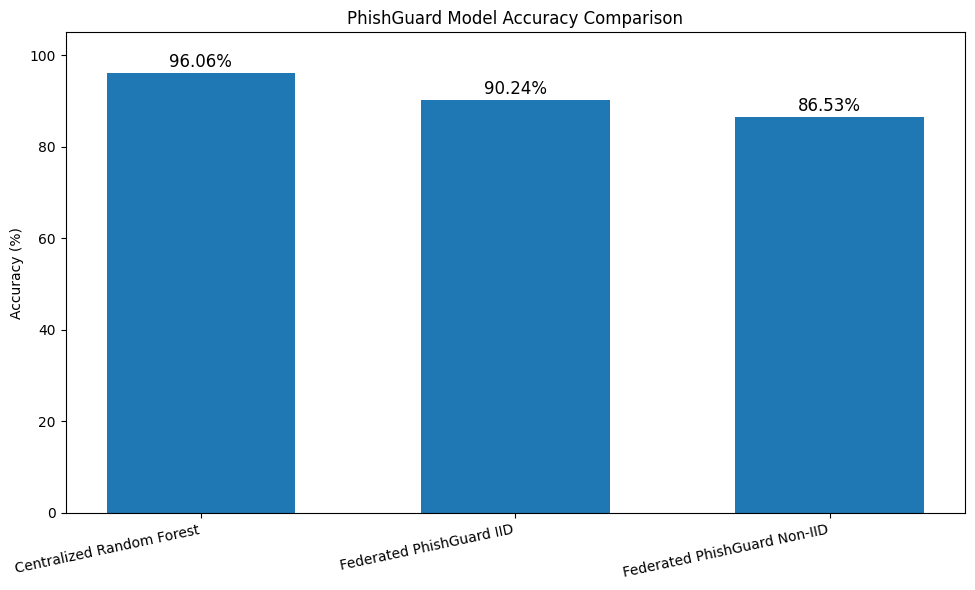

In [39]:
import matplotlib.pyplot as plt
import pandas as pd

results = pd.read_csv("/content/phishguard_results.csv")

plt.figure(figsize=(10, 6))

bars = plt.bar(
    results["Model"],
    results["Accuracy"],
    width=0.6
)

# Add percentage labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.5,
        f"{height:.2f}%",
        ha="center",
        va="bottom",
        fontsize=12
    )

plt.ylabel("Accuracy (%)")
plt.title("PhishGuard Model Accuracy Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=12, ha="right")
plt.tight_layout()

plt.savefig(
    "accuracy_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

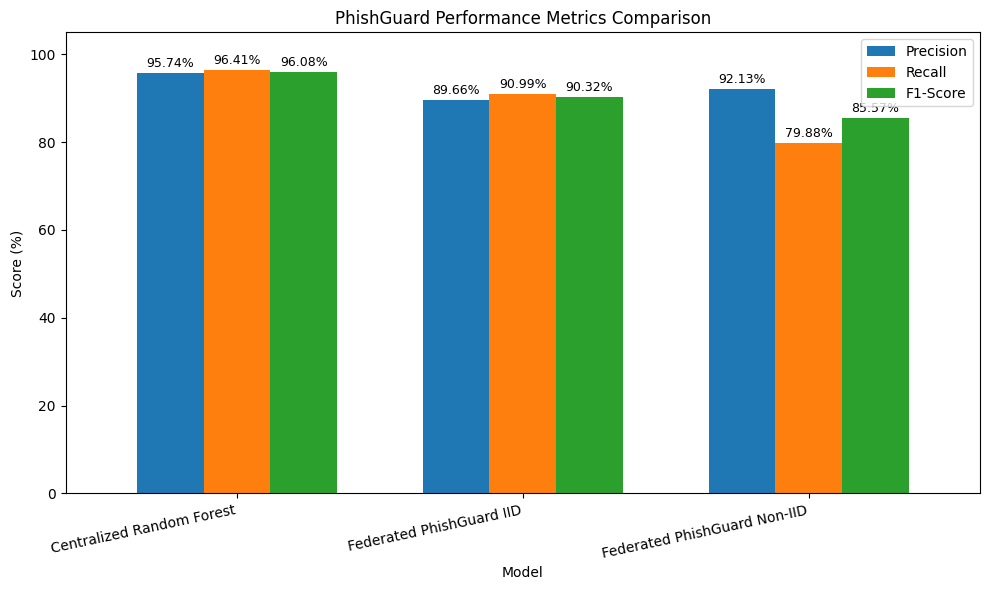

Graph 2 saved!


In [41]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv("/content/phishguard_results.csv")

metrics = ["Precision", "Recall", "F1_Score"]

ax = results.plot(
    x="Model",
    y=metrics,
    kind="bar",
    figsize=(10, 6),
    width=0.7
)

plt.ylabel("Score (%)")
plt.title("PhishGuard Performance Metrics Comparison")
plt.ylim(0, 105)
plt.xticks(rotation=12, ha="right")
plt.legend(["Precision", "Recall", "F1-Score"])

# Add percentage labels
for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.2f%%",
        fontsize=9,
        padding=2
    )

plt.tight_layout()

plt.savefig(
    "performance_metrics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph 2 saved!")

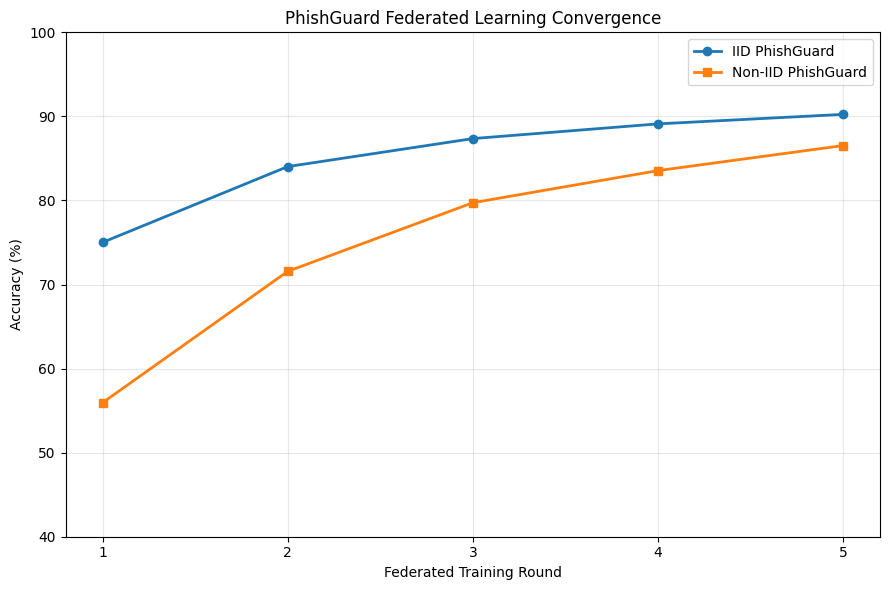

Graph 3 saved!


In [42]:
import matplotlib.pyplot as plt

rounds = [1, 2, 3, 4, 5]

iid_accuracy = [75.02, 84.03, 87.36, 89.11, 90.24]

noniid_accuracy = [55.95, 71.57, 79.73, 83.55, 86.53]

plt.figure(figsize=(9, 6))

plt.plot(
    rounds,
    iid_accuracy,
    marker="o",
    linewidth=2,
    label="IID PhishGuard"
)

plt.plot(
    rounds,
    noniid_accuracy,
    marker="s",
    linewidth=2,
    label="Non-IID PhishGuard"
)

plt.xlabel("Federated Training Round")
plt.ylabel("Accuracy (%)")
plt.title("PhishGuard Federated Learning Convergence")

plt.xticks(rounds)
plt.ylim(40, 100)
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()

plt.savefig(
    "iid_vs_noniid.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Graph 3 saved!")